In [8]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


In [9]:
# Carregamento do conjunto de dados Iris
iris = load_iris()

X = iris.data
y = iris.target

dados = pd.DataFrame(X, columns=iris.feature_names)
dados["especie"] = pd.Categorical.from_codes(y, iris.target_names)

print("Quantidade de exemplos:", len(dados))
display(dados.head())
display(dados["especie"].value_counts())

Quantidade de exemplos: 150


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [10]:
# Divisão entre treinamento e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Padronização dos dados
scaler = StandardScaler()

X_treino_padronizado = scaler.fit_transform(X_treino)
X_teste_padronizado = scaler.transform(X_teste)

print("Dados de treinamento:", X_treino_padronizado.shape)
print("Dados de teste:", X_teste_padronizado.shape)

Dados de treinamento: (120, 4)
Dados de teste: (30, 4)


In [11]:
# Construção da rede neural
modelo = tf.keras.Sequential([
    tf.keras.Input(shape=(4,)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo.summary()

parada_antecipada = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

historico = modelo.fit(
    X_treino_padronizado,
    y_treino,
    validation_split=0.20,
    epochs=200,
    batch_size=16,
    callbacks=[parada_antecipada],
    verbose=0
)

print("Treinamento concluído!")
print("Épocas executadas:", len(historico.history["loss"]))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

Treinamento concluído!
Épocas executadas: 64


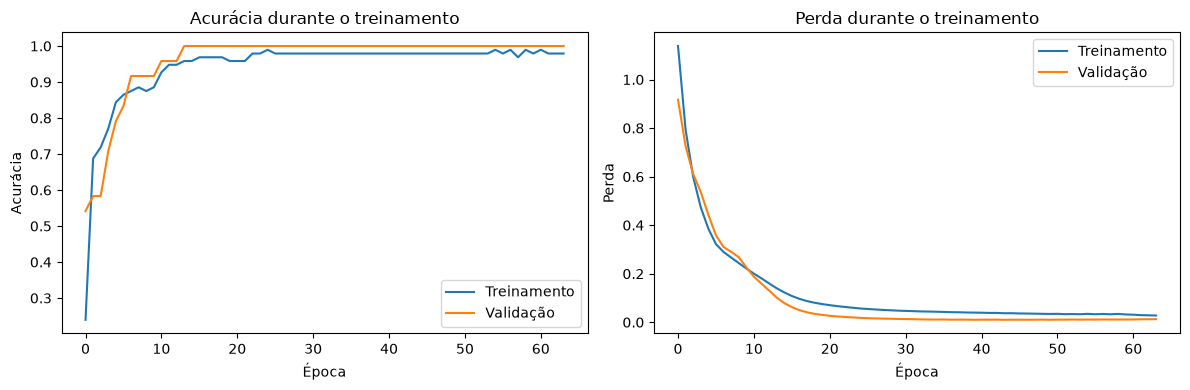

In [12]:
# Gráficos do treinamento
figura, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].plot(historico.history["accuracy"], label="Treinamento")
eixos[0].plot(historico.history["val_accuracy"], label="Validação")
eixos[0].set_title("Acurácia durante o treinamento")
eixos[0].set_xlabel("Época")
eixos[0].set_ylabel("Acurácia")
eixos[0].legend()

eixos[1].plot(historico.history["loss"], label="Treinamento")
eixos[1].plot(historico.history["val_loss"], label="Validação")
eixos[1].set_title("Perda durante o treinamento")
eixos[1].set_xlabel("Época")
eixos[1].set_ylabel("Perda")
eixos[1].legend()

plt.tight_layout()
plt.show()

Acurácia no conjunto de teste: 96.67%

Relatório de classificação:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



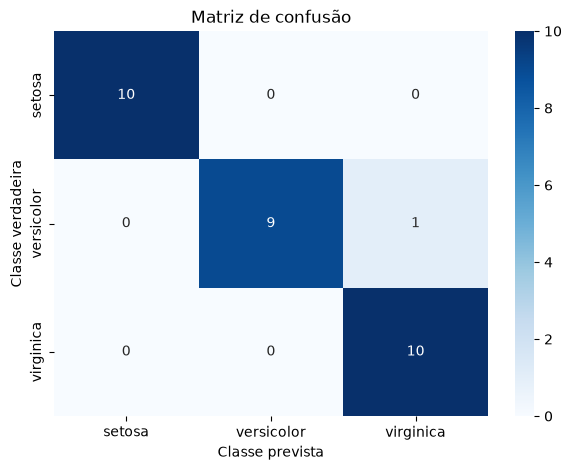

In [13]:
# Avaliação do modelo
perda, acuracia = modelo.evaluate(
    X_teste_padronizado,
    y_teste,
    verbose=0
)

probabilidades = modelo.predict(X_teste_padronizado, verbose=0)
previsoes = np.argmax(probabilidades, axis=1)

print(f"Acurácia no conjunto de teste: {acuracia:.2%}")
print("\nRelatório de classificação:")
print(
    classification_report(
        y_teste,
        previsoes,
        target_names=iris.target_names
    )
)

matriz = confusion_matrix(y_teste, previsoes)

plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.title("Matriz de confusão")
plt.xlabel("Classe prevista")
plt.ylabel("Classe verdadeira")
plt.show()

In [14]:
# Previsões com novas flores
novas_flores = np.array([
    [5.1, 3.5, 1.4, 0.2],
    [6.0, 2.9, 4.5, 1.5],
    [6.5, 3.0, 5.8, 2.2]
])

novas_flores_padronizadas = scaler.transform(novas_flores)
novas_probabilidades = modelo.predict(
    novas_flores_padronizadas,
    verbose=0
)

novas_previsoes = np.argmax(novas_probabilidades, axis=1)

resultado = pd.DataFrame(
    novas_flores,
    columns=iris.feature_names
)

resultado["previsao"] = iris.target_names[novas_previsoes]
resultado["confianca"] = novas_probabilidades.max(axis=1)

display(resultado)

assert len(resultado) == 3
assert np.allclose(novas_probabilidades.sum(axis=1), 1, atol=1e-5)
assert acuracia >= 0.80

print("Todos os testes foram concluídos com sucesso!")

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),previsao,confianca
0,5.1,3.5,1.4,0.2,setosa,0.999764
1,6.0,2.9,4.5,1.5,versicolor,0.993228
2,6.5,3.0,5.8,2.2,virginica,0.999993


Todos os testes foram concluídos com sucesso!
